<a href="https://colab.research.google.com/github/symbat-omirali/student-dropout-prediction/blob/main/student_dropout_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [73]:
!pip install ucimlrepo

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [75]:
# Load dataset from UCI Repository

student_data = fetch_ucirepo(id=697)

# Separate features and target

X = student_data.data.features
y = student_data.data.targets

# Combine features and target

df = pd.concat([X, y], axis=1)

print("Dataset successfully loaded!")

Dataset successfully loaded!


In [76]:
# Display first 5 rows

df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [77]:
# Check dataset dimensions

print("Dataset shape:", df.shape)

Dataset shape: (4424, 37)


In [78]:
# Display column names

print(df.columns.tolist())

['Marital Status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [79]:
print(df["Target"].value_counts())

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [80]:
# Check data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [81]:
# Check missing values

print(df.isnull().sum())

Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [82]:
# Check duplicate rows

print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [83]:
# Display all column names with their index

for i, column in enumerate(df.columns):
    print(i, column)

0 Marital Status
1 Application mode
2 Application order
3 Course
4 Daytime/evening attendance
5 Previous qualification
6 Previous qualification (grade)
7 Nacionality
8 Mother's qualification
9 Father's qualification
10 Mother's occupation
11 Father's occupation
12 Admission grade
13 Displaced
14 Educational special needs
15 Debtor
16 Tuition fees up to date
17 Gender
18 Scholarship holder
19 Age at enrollment
20 International
21 Curricular units 1st sem (credited)
22 Curricular units 1st sem (enrolled)
23 Curricular units 1st sem (evaluations)
24 Curricular units 1st sem (approved)
25 Curricular units 1st sem (grade)
26 Curricular units 1st sem (without evaluations)
27 Curricular units 2nd sem (credited)
28 Curricular units 2nd sem (enrolled)
29 Curricular units 2nd sem (evaluations)
30 Curricular units 2nd sem (approved)
31 Curricular units 2nd sem (grade)
32 Curricular units 2nd sem (without evaluations)
33 Unemployment rate
34 Inflation rate
35 GDP
36 Target


In [84]:
# Statistical summary of numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [85]:
categorical_columns = [
    "Gender",
    "Marital Status",
    "Daytime/evening attendance",
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
    "Target"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Gender
Gender
0    2868
1    1556
Name: count, dtype: int64

 Marital Status
Marital Status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: int64

 Daytime/evening attendance
Daytime/evening attendance
1    3941
0     483
Name: count, dtype: int64

 Debtor
Debtor
0    3921
1     503
Name: count, dtype: int64

 Tuition fees up to date
Tuition fees up to date
1    3896
0     528
Name: count, dtype: int64

 Scholarship holder
Scholarship holder
0    3325
1    1099
Name: count, dtype: int64

 Target
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [86]:
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


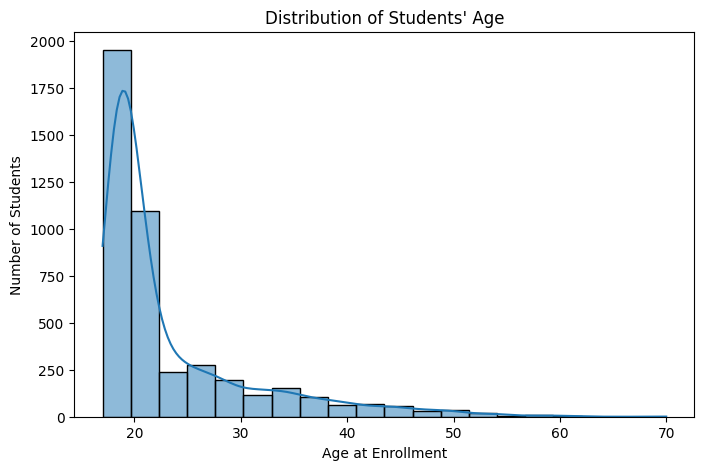

In [87]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    bins=20,
    kde=True
)

plt.title("Distribution of Students' Age")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.show()

In [88]:
# Average age by academic outcome

age_analysis = df.groupby("Target")["Age at enrollment"].agg(
    ["mean", "median", "min", "max", "count"]
)

print(age_analysis)

               mean  median  min  max  count
Target                                      
Dropout   26.068966    23.0   18   70   1421
Enrolled  22.369018    20.0   17   54    794
Graduate  21.783612    19.0   17   62   2209


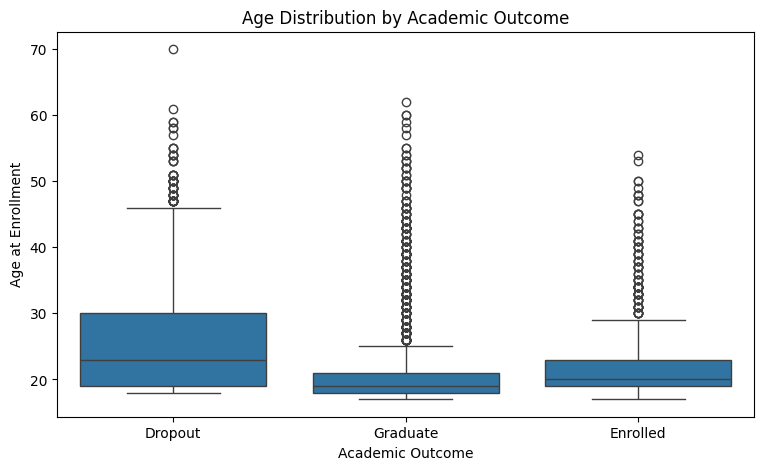

In [89]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment"
)

plt.title("Age Distribution by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("Age at Enrollment")

plt.show()

In [90]:
scholarship_analysis = pd.crosstab(
    df["Scholarship holder"],
    df["Target"],
    normalize="index"
) * 100

print(scholarship_analysis.round(2))

Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                     38.71     19.97     41.32
1                     12.19     11.83     75.98


In [91]:
debtor_analysis = pd.crosstab(
    df["Debtor"],
    df["Target"],
    normalize="index"
) * 100

print(debtor_analysis.round(2))

Target  Dropout  Enrolled  Graduate
Debtor                             
0         28.28     17.95     53.76
1         62.03     17.89     20.08


In [92]:
from scipy.stats import chi2_contingency

# Scholarship and academic outcome
scholarship_table = pd.crosstab(
    df["Scholarship holder"],
    df["Target"]
)

chi2_s, p_s, dof_s, expected_s = chi2_contingency(
    scholarship_table
)

print("Scholarship analysis")
print("Chi-square:", chi2_s)
print("P-value:", p_s)

Scholarship analysis
Chi-square: 409.94305544699375
P-value: 9.593930375514133e-90


In [93]:
debtor_table = pd.crosstab(
    df["Debtor"],
    df["Target"]
)

chi2_d, p_d, dof_d, expected_d = chi2_contingency(
    debtor_table
)

print("Debtor analysis")
print("Chi-square:", chi2_d)
print("P-value:", p_d)

Debtor analysis
Chi-square: 259.33321964832965
P-value: 4.858552123231672e-57


In [94]:
import numpy as np

# Calculate Cramer's V

def cramers_v(chi2, n, rows, cols):
    return np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

# Scholarship
v_scholarship = cramers_v(
    chi2_s,
    len(df),
    scholarship_table.shape[0],
    scholarship_table.shape[1]
)

# Debtor
v_debtor = cramers_v(
    chi2_d,
    len(df),
    debtor_table.shape[0],
    debtor_table.shape[1]
)

print("Scholarship Cramer's V:", round(v_scholarship, 4))
print("Debtor Cramer's V:", round(v_debtor, 4))

Scholarship Cramer's V: 0.3044
Debtor Cramer's V: 0.2421


In [95]:
# Identify second-semester features

second_semester_features = [
    col for col in df.columns
    if "2nd sem" in col
]

print(second_semester_features)

['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


In [96]:
# Remove second-semester features

df_model = df.drop(
    columns=second_semester_features
)

print("Original shape:", df.shape)
print("New shape:", df_model.shape)

Original shape: (4424, 37)
New shape: (4424, 31)


In [97]:
# Define features and target

X = df_model.drop(columns=["Target"])
y = df_model["Target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4424, 30)
Target shape: (4424,)


In [98]:
print(X.dtypes.value_counts())

int64      24
float64     6
Name: count, dtype: int64


In [99]:
print("Number of features:", X.shape[1])

Number of features: 30


In [100]:
categorical_features = [
    "Marital Status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

In [101]:
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

In [102]:
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nNumerical columns:")
print(numerical_features)

Categorical features: 17
Numerical features: 13

Numerical columns:
['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


In [103]:
print("Categorical:", len(categorical_features))
print("Numerical:", len(numerical_features))

# Check that all features are assigned
assert len(categorical_features) + len(numerical_features) == X.shape[1]

# Check for overlapping columns
assert set(categorical_features).isdisjoint(set(numerical_features))

print("\nFeature classification is correct!")

Categorical: 17
Numerical: 13

Feature classification is correct!


In [104]:
from sklearn.model_selection import train_test_split

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3539, 30)
Testing data: (885, 30)


In [106]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training target distribution:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Testing target distribution:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


In [107]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [108]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [109]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

In [110]:
logistic_model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [111]:
# Make predictions on test data

y_pred = logistic_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['Graduate' 'Graduate' 'Enrolled' 'Graduate' 'Graduate' 'Dropout'
 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Enrolled'
 'Dropout' 'Dropout' 'Graduate' 'Enrolled' 'Graduate' 'Dropout' 'Dropout'
 'Dropout']


In [112]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2))

Accuracy: 0.748
Accuracy (%): 74.8


In [113]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Dropout       0.79      0.75      0.77       284
    Enrolled       0.49      0.33      0.40       159
    Graduate       0.78      0.89      0.83       442

    accuracy                           0.75       885
   macro avg       0.69      0.66      0.67       885
weighted avg       0.73      0.75      0.74       885



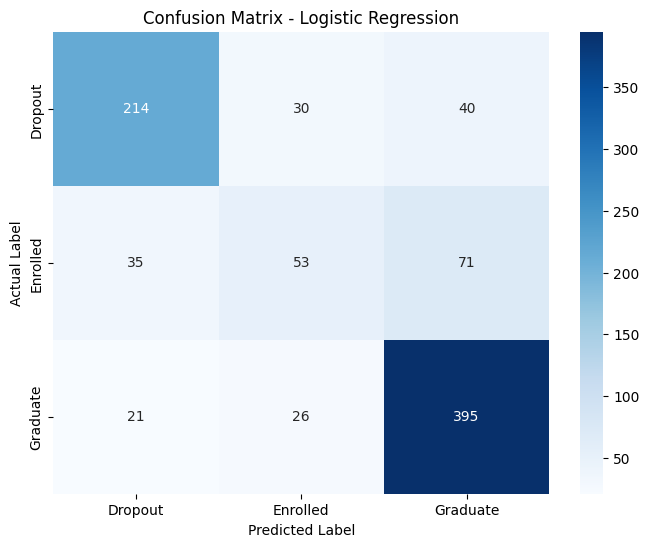

In [114]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Dropout", "Enrolled", "Graduate"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dropout", "Enrolled", "Graduate"],
    yticklabels=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [115]:
from sklearn.ensemble import RandomForestClassifier

In [116]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=2,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

In [117]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [118]:
rf_pred = rf_model.predict(X_test)

In [119]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

rf_accuracy = accuracy_score(y_test, rf_pred)

rf_macro_f1 = f1_score(
    y_test,
    rf_pred,
    average="macro"
)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest Macro F1:", round(rf_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.7254
Random Forest Macro F1: 0.6202

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.76      0.70      0.73       284
    Enrolled       0.49      0.23      0.31       159
    Graduate       0.74      0.92      0.82       442

    accuracy                           0.73       885
   macro avg       0.66      0.62      0.62       885
weighted avg       0.70      0.73      0.70       885



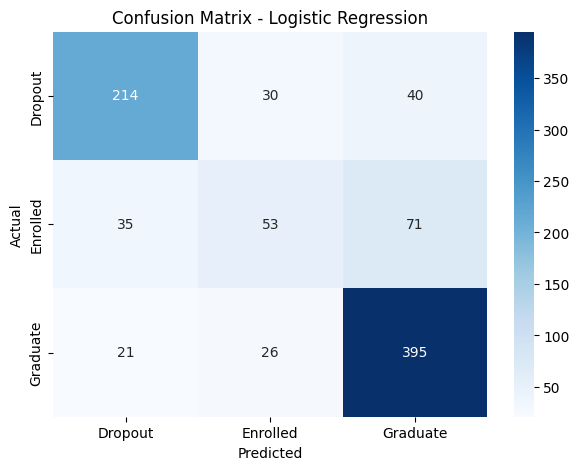

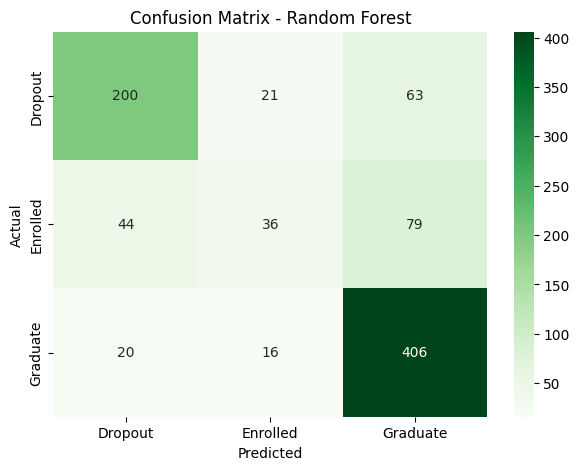

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Logistic Regression
lr_cm = confusion_matrix(
    y_test,
    logistic_model.predict(X_test),
    labels=["Dropout", "Enrolled", "Graduate"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dropout", "Enrolled", "Graduate"],
    yticklabels=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Random Forest
rf_cm = confusion_matrix(
    y_test,
    rf_model.predict(X_test),
    labels=["Dropout", "Enrolled", "Graduate"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Dropout", "Enrolled", "Graduate"],
    yticklabels=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [121]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

# Logistic Regression
lr_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Random Forest
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression:")
print("Accuracy:", lr_cv_results["test_accuracy"].mean())
print("Macro F1:", lr_cv_results["test_f1_macro"].mean())

print("\nRandom Forest:")
print("Accuracy:", rf_cv_results["test_accuracy"].mean())
print("Macro F1:", rf_cv_results["test_f1_macro"].mean())

Logistic Regression:
Accuracy: 0.7482271713854194
Macro F1: 0.6608755503835038

Random Forest:
Accuracy: 0.7394705087942208
Macro F1: 0.6305858422216831


In [122]:
from sklearn.model_selection import GridSearchCV

# Parameters to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

# Train on training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best Cross-Validation Macro F1:
0.6838840063270752


In [123]:
{
    "classifier__C": 0.1,
    "classifier__class_weight": "balanced"
}

{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

In [124]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(rf_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Random Forest parameters:
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 20, 'classifier__class_weight': 'balanced'}

Best Cross-Validation Macro F1:
0.6849940050410189


In [125]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Best models
best_lr_model = grid_search.best_estimator_
best_rf_model = rf_search.best_estimator_

# Predictions
best_lr_pred = best_lr_model.predict(X_test)
best_rf_pred = best_rf_model.predict(X_test)

# Evaluation function
def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

# Evaluate both models
evaluate_model("Tuned Logistic Regression", y_test, best_lr_pred)
evaluate_model("Tuned Random Forest", y_test, best_rf_pred)


Tuned Logistic Regression
----------------------------------------
Accuracy: 0.7073446327683616
Macro F1: 0.6677619730327097

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.80      0.66      0.72       284
    Enrolled       0.40      0.59      0.47       159
    Graduate       0.83      0.78      0.81       442

    accuracy                           0.71       885
   macro avg       0.68      0.68      0.67       885
weighted avg       0.74      0.71      0.72       885


Tuned Random Forest
----------------------------------------
Accuracy: 0.7197740112994351
Macro F1: 0.6611551336912328

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.75      0.70      0.73       284
    Enrolled       0.42      0.45      0.44       159
    Graduate       0.82      0.83      0.82       442

    accuracy                           0.72       885
   macro avg       0.66      0.66      0.66       885

In [126]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Calculate permutation importance
lr_importance = permutation_importance(
    best_lr_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": lr_importance.importances_mean,
    "Std": lr_importance.importances_std
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(importance_df.head(15))

,Feature,Importance,Std
24,Curricular units 1st sem (approved),0.212963,0.012807
16,Tuition fees up to date,0.043716,0.005587
22,Curricular units 1st sem (enrolled),0.030246,0.009105
25,Curricular units 1st sem (grade),0.030132,0.006697
23,Curricular units 1st sem (evaluations),0.029343,0.009405
3,Course,0.013681,0.007126
15,Debtor,0.012164,0.004766
11,Father's occupation,0.009572,0.006104
19,Age at enrollment,0.008814,0.004537
27,Unemployment rate,0.007971,0.006615


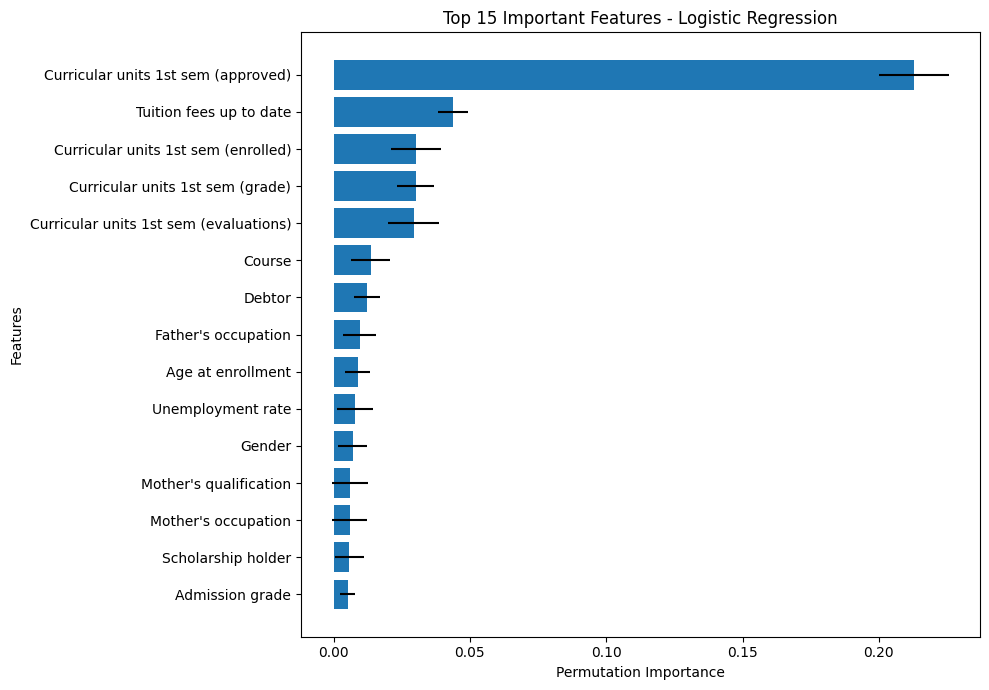

In [127]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Logistic Regression")
plt.tight_layout()
plt.show()

In [128]:
!pip install shap

In [129]:
# Get the fitted preprocessing step
preprocessor_fitted = best_lr_model.named_steps["preprocessor"]

# Transform train and test data
X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Convert arrays to DataFrames
X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=feature_names
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names
)

# Check the results
print("Training shape:", X_train_transformed_df.shape)
print("Test shape:", X_test_transformed_df.shape)
print("Number of feature names:", len(feature_names))
print("First 20 features:", feature_names[:20])

Training shape: (3539, 238)
Test shape: (885, 238)
Number of feature names: 238
First 20 features: ['num__Application order' 'num__Previous qualification (grade)'
 'num__Admission grade' 'num__Age at enrollment'
 'num__Curricular units 1st sem (credited)'
 'num__Curricular units 1st sem (enrolled)'
 'num__Curricular units 1st sem (evaluations)'
 'num__Curricular units 1st sem (approved)'
 'num__Curricular units 1st sem (grade)'
 'num__Curricular units 1st sem (without evaluations)'
 'num__Unemployment rate' 'num__Inflation rate' 'num__GDP'
 'cat__Marital Status_1' 'cat__Marital Status_2' 'cat__Marital Status_3'
 'cat__Marital Status_4' 'cat__Marital Status_5' 'cat__Marital Status_6'
 'cat__Application mode_1']


In [130]:
!pip install shap -q

import shap
import numpy as np
import matplotlib.pyplot as plt

# Get the fitted Logistic Regression classifier
classifier_fitted = best_lr_model.named_steps["classifier"]

# Select a small background sample
X_background = X_train_transformed_df.sample(
    n=100,
    random_state=42
)

# Select test observations to explain
X_explain = X_test_transformed_df.sample(
    n=200,
    random_state=42
)

# Create SHAP explainer
explainer = shap.Explainer(
    classifier_fitted,
    X_background
)

# Calculate SHAP values
shap_values = explainer(X_explain)

print("SHAP values shape:", shap_values.values.shape)
print("Model classes:", classifier_fitted.classes_)

SHAP values shape: (200, 238, 3)
Model classes: ['Dropout' 'Enrolled' 'Graduate']


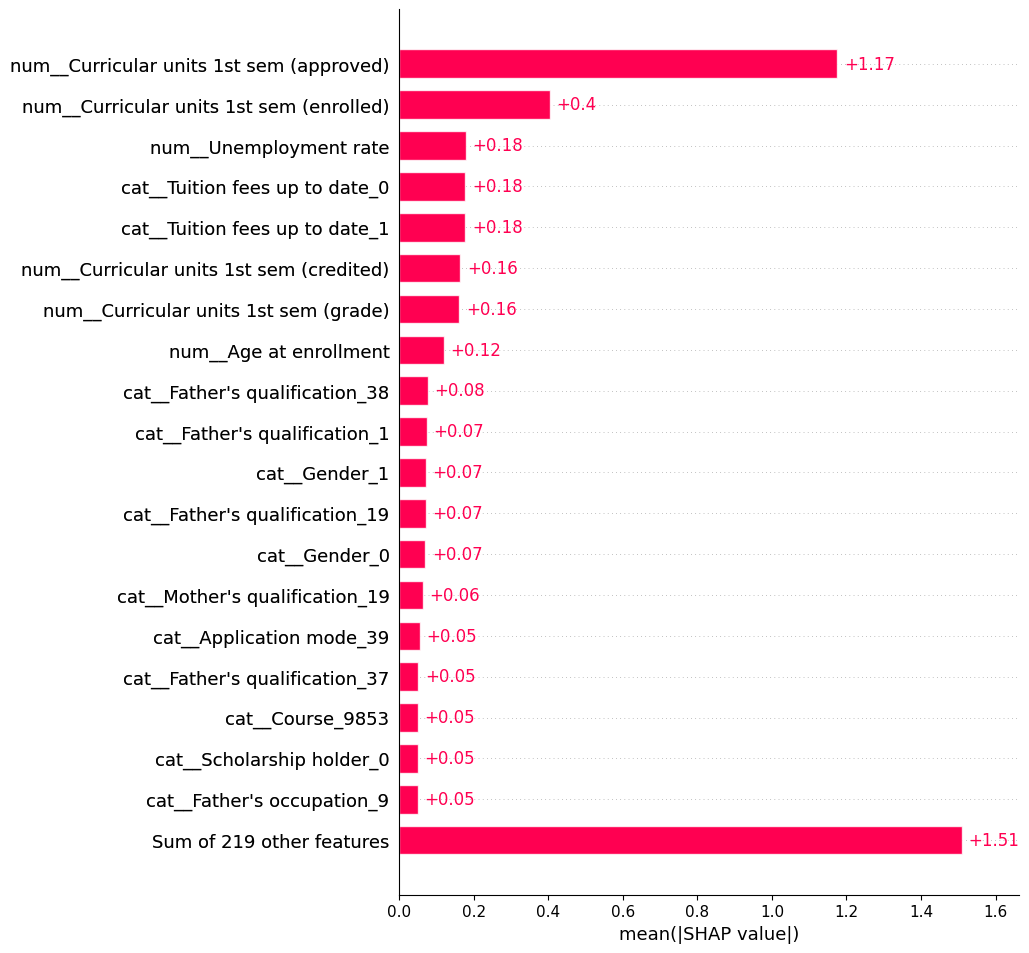

In [131]:
# Select SHAP values for the Dropout class
dropout_shap = shap_values[:, :, 0]

# Global feature importance
shap.plots.bar(dropout_shap, max_display=20)

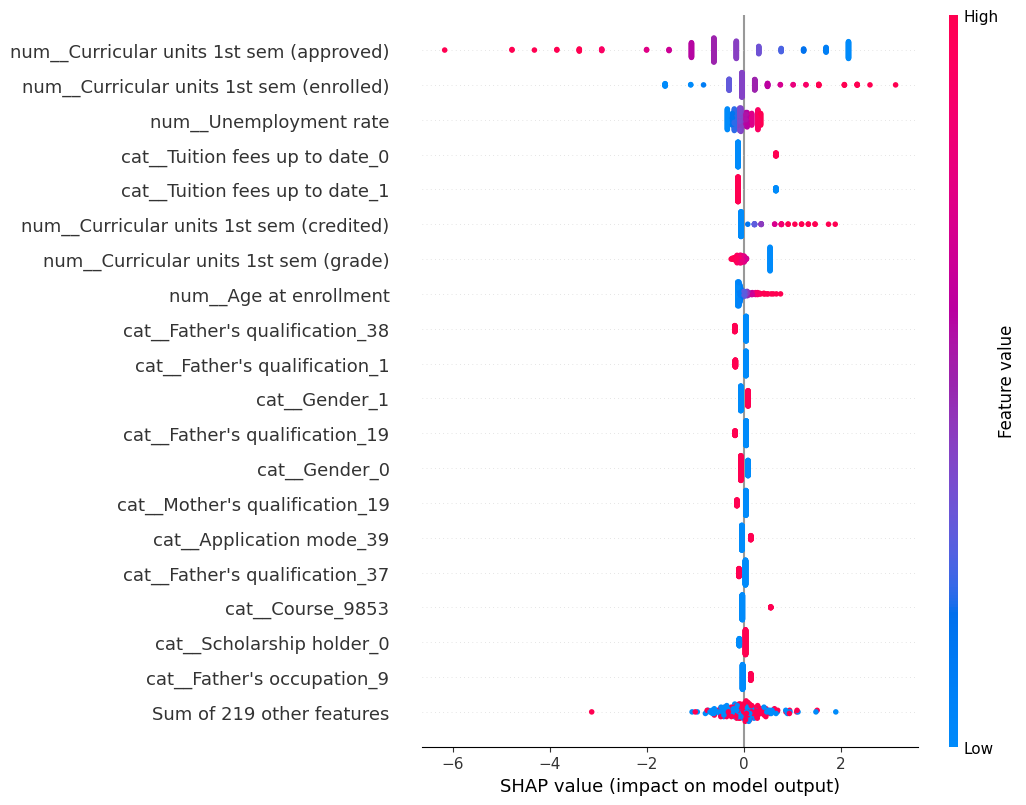

In [132]:
shap.plots.beeswarm(dropout_shap, max_display=20)

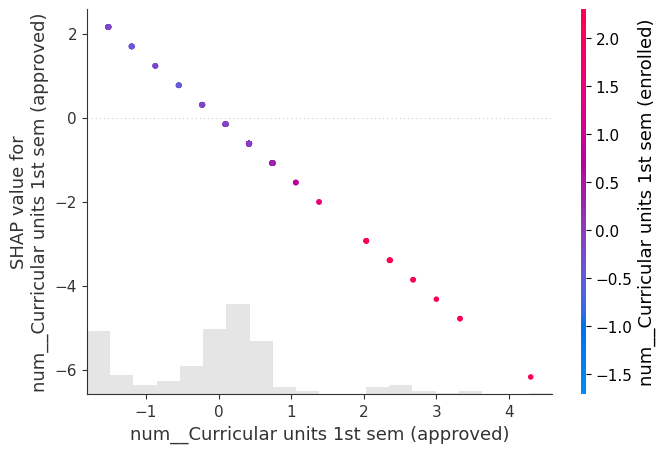

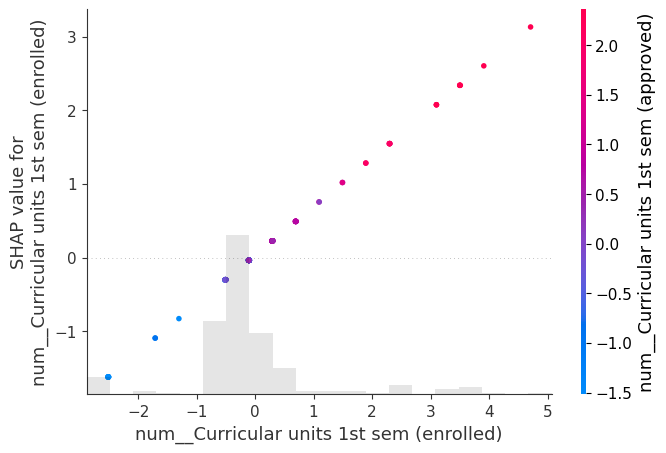

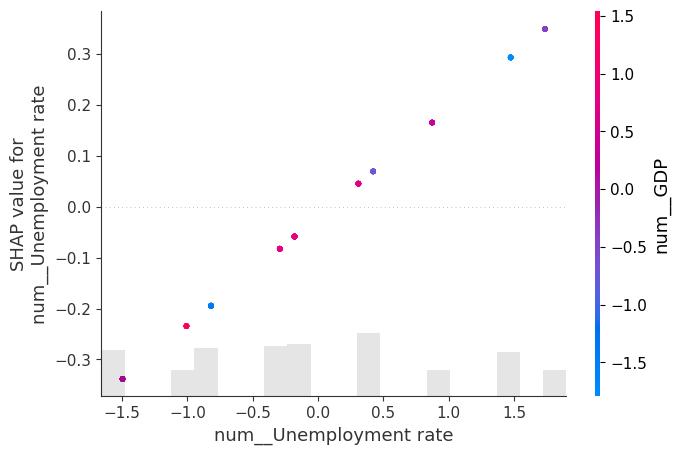

In [133]:
# Create dependence plots for the most important features

features_to_plot = [
    "num__Curricular units 1st sem (approved)",
    "num__Curricular units 1st sem (enrolled)",
    "num__Unemployment rate"
]

for feature in features_to_plot:
    shap.plots.scatter(
        dropout_shap[:, feature],
        color=dropout_shap
    )

In [134]:
# Calculate mean absolute SHAP values
shap_importance = np.abs(dropout_shap.values).mean(axis=0)

# Create a table
shap_results = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean_SHAP": shap_importance
})

# Sort by importance
shap_results = shap_results.sort_values(
    by="Mean_SHAP",
    ascending=False
)

# Display top 25 features
print(shap_results.head(25).to_string(index=False))

                                 Feature  Mean_SHAP
num__Curricular units 1st sem (approved)   1.174930
num__Curricular units 1st sem (enrolled)   0.404424
                  num__Unemployment rate   0.179116
          cat__Tuition fees up to date_0   0.177508
          cat__Tuition fees up to date_1   0.177210
num__Curricular units 1st sem (credited)   0.164047
   num__Curricular units 1st sem (grade)   0.161695
                  num__Age at enrollment   0.118991
          cat__Father's qualification_38   0.076235
           cat__Father's qualification_1   0.073881
                           cat__Gender_1   0.071091
          cat__Father's qualification_19   0.070964
                           cat__Gender_0   0.070465
          cat__Mother's qualification_19   0.062955
                cat__Application mode_39   0.054431
          cat__Father's qualification_37   0.051394
                        cat__Course_9853   0.050480
               cat__Scholarship holder_0   0.049262
            

In [135]:
# Select the 10 most important features
top_features = shap_results["Feature"].head(10)

for feature in top_features:

    feature_values = X_explain[feature].values
    feature_shap = dropout_shap[:, feature].values

    print("\nFeature:", feature)
    print("Mean absolute SHAP:", np.abs(feature_shap).mean())
    print("Mean SHAP:", feature_shap.mean())

    print("Correlation between feature and SHAP:",
          np.corrcoef(feature_values, feature_shap)[0, 1])

    print("Mean SHAP for low feature values:",
          feature_shap[feature_values <= np.median(feature_values)].mean())

    print("Mean SHAP for high feature values:",
          feature_shap[feature_values > np.median(feature_values)].mean())


Feature: num__Curricular units 1st sem (approved)
Mean absolute SHAP: 1.1749298581079122
Mean SHAP: -0.12957083901938382
Correlation between feature and SHAP: -0.9999999999999974
Mean SHAP for low feature values: 0.9552289739244955
Mean SHAP for high feature values: -1.3047706363752531

Feature: num__Curricular units 1st sem (enrolled)
Mean absolute SHAP: 0.4044235414554364
Mean SHAP: 0.08319841663953925
Correlation between feature and SHAP: 0.999999999999996
Mean SHAP for low feature values: -0.24152265023751676
Mean SHAP for high feature values: 0.7277939673059338

Feature: num__Unemployment rate
Mean absolute SHAP: 0.1791155553183145
Mean SHAP: -0.020733741314983026
Correlation between feature and SHAP: 0.9999999999999998
Mean SHAP for low feature values: -0.1722838764080151
Mean SHAP for high feature values: 0.1885497785753946

Feature: cat__Tuition fees up to date_0
Mean absolute SHAP: 0.17750799703854214
Mean SHAP: -0.03127894220943474
Correlation between feature and SHAP: 0.999

/tmp/ipykernel_2787/2577952489.py:20: RuntimeWarning: Mean of empty slice.
  feature_shap[feature_values > np.median(feature_values)].mean())
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [136]:
binary_features = [
    "cat__Tuition fees up to date_0",
    "cat__Tuition fees up to date_1",
    "cat__Gender_0",
    "cat__Gender_1",
    "cat__Scholarship holder_0",
    "cat__Scholarship holder_1"
]

for feature in binary_features:

    feature_values = X_explain[feature].values
    feature_shap = dropout_shap[:, feature].values

    print("\nFeature:", feature)

    for value in [0, 1]:
        mask = feature_values == value

        if mask.sum() > 0:
            print(
                f"Value {value}:",
                "Count =", mask.sum(),
                "| Mean SHAP =", round(feature_shap[mask].mean(), 4)
            )


Feature: cat__Tuition fees up to date_0
Value 0: Count = 178 | Mean SHAP = -0.1173
Value 1: Count = 22 | Mean SHAP = 0.6647

Feature: cat__Tuition fees up to date_1
Value 0: Count = 22 | Mean SHAP = 0.6636
Value 1: Count = 178 | Mean SHAP = -0.1171

Feature: cat__Gender_0
Value 0: Count = 77 | Mean SHAP = 0.0886
Value 1: Count = 123 | Mean SHAP = -0.0591

Feature: cat__Gender_1
Value 0: Count = 123 | Mean SHAP = -0.0596
Value 1: Count = 77 | Mean SHAP = 0.0894

Feature: cat__Scholarship holder_0
Value 0: Count = 45 | Mean SHAP = -0.091
Value 1: Count = 155 | Mean SHAP = 0.0372

Feature: cat__Scholarship holder_1
Value 0: Count = 155 | Mean SHAP = 0.0368
Value 1: Count = 45 | Mean SHAP = -0.09


In [137]:
# Explain the entire test dataset
shap_values_full = explainer(X_test_transformed_df)

# Select Dropout class (class index 0)
dropout_shap_full = shap_values_full[:, :, 0]

# Calculate global SHAP importance
shap_importance_full = np.abs(
    dropout_shap_full.values
).mean(axis=0)

shap_results_full = pd.DataFrame({
    "Feature": X_test_transformed_df.columns,
    "Mean_absolute_SHAP": shap_importance_full
})

shap_results_full = shap_results_full.sort_values(
    by="Mean_absolute_SHAP",
    ascending=False
)

print(shap_results_full.head(25).to_string(index=False))

                                 Feature  Mean_absolute_SHAP
num__Curricular units 1st sem (approved)            1.052551
num__Curricular units 1st sem (enrolled)            0.348647
          cat__Tuition fees up to date_0            0.184714
          cat__Tuition fees up to date_1            0.184404
                  num__Unemployment rate            0.184393
   num__Curricular units 1st sem (grade)            0.150917
num__Curricular units 1st sem (credited)            0.136278
                  num__Age at enrollment            0.120840
          cat__Father's qualification_19            0.077839
           cat__Father's qualification_1            0.072776
          cat__Father's qualification_38            0.070411
                           cat__Gender_1            0.070225
                           cat__Gender_0            0.069606
          cat__Mother's qualification_19            0.063326
                cat__Application mode_39            0.058758
          cat__Father's 

In [138]:
binary_features = [
    "cat__Tuition fees up to date_0",
    "cat__Tuition fees up to date_1",
    "cat__Gender_0",
    "cat__Gender_1",
    "cat__Scholarship holder_0",
    "cat__Scholarship holder_1"
]

for feature in binary_features:
    feature_values = X_test_transformed_df[feature].values
    feature_shap = dropout_shap_full[:, feature].values

    print("\nFeature:", feature)

    for value in [0, 1]:
        mask = feature_values == value

        print(
            f"Value {value}:",
            "Count =", mask.sum(),
            "| Mean SHAP =", round(feature_shap[mask].mean(), 4)
        )


Feature: cat__Tuition fees up to date_0
Value 0: Count = 776 | Mean SHAP = -0.1173
Value 1: Count = 109 | Mean SHAP = 0.6647

Feature: cat__Tuition fees up to date_1
Value 0: Count = 109 | Mean SHAP = 0.6636
Value 1: Count = 776 | Mean SHAP = -0.1171

Feature: cat__Gender_0
Value 0: Count = 315 | Mean SHAP = 0.0886
Value 1: Count = 570 | Mean SHAP = -0.0591

Feature: cat__Gender_1
Value 0: Count = 570 | Mean SHAP = -0.0596
Value 1: Count = 315 | Mean SHAP = 0.0894

Feature: cat__Scholarship holder_0
Value 0: Count = 205 | Mean SHAP = -0.091
Value 1: Count = 680 | Mean SHAP = 0.0372

Feature: cat__Scholarship holder_1
Value 0: Count = 680 | Mean SHAP = 0.0368
Value 1: Count = 205 | Mean SHAP = -0.09



SHAP analysis for: Dropout


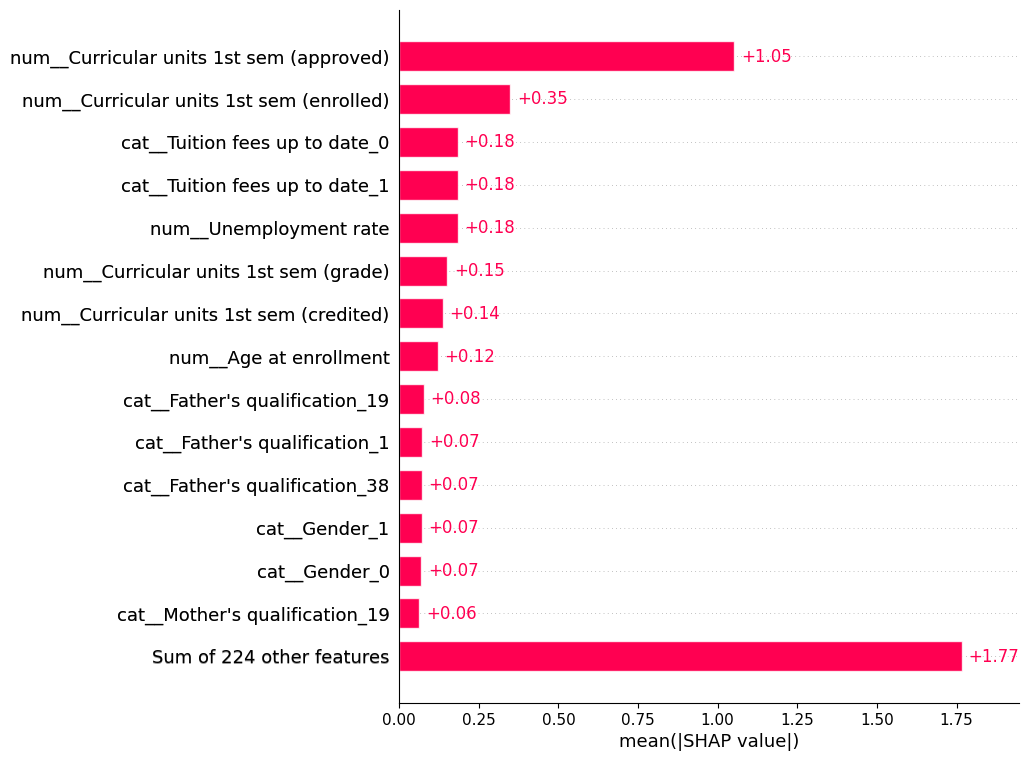


SHAP analysis for: Enrolled


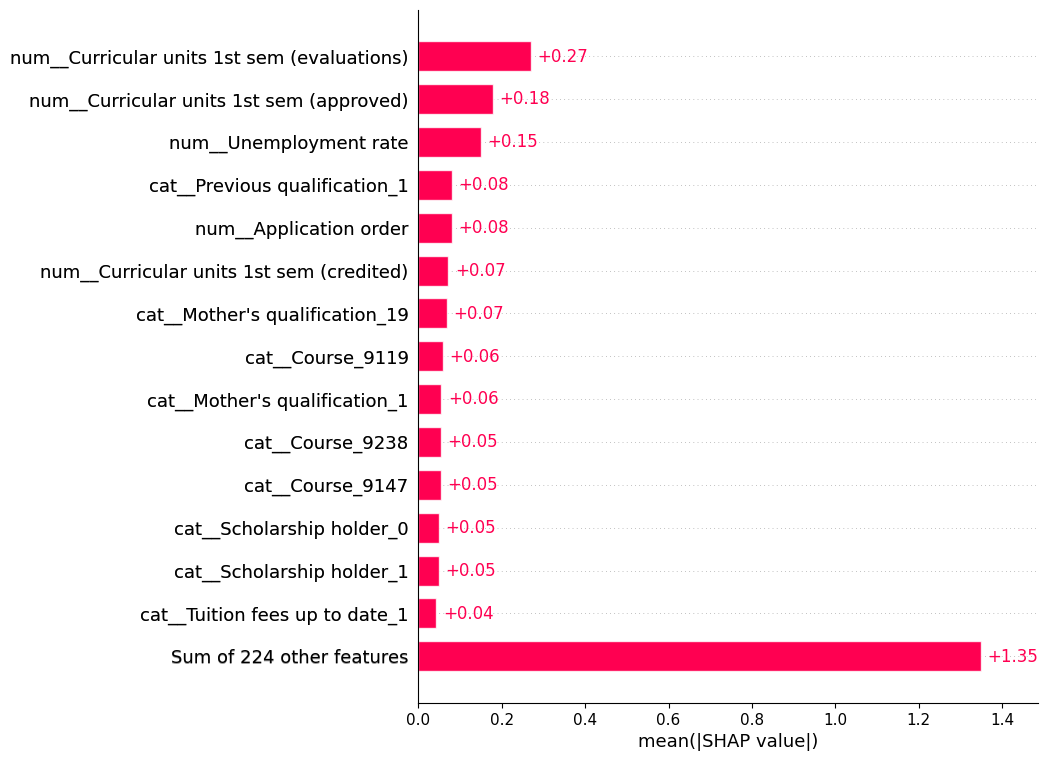


SHAP analysis for: Graduate


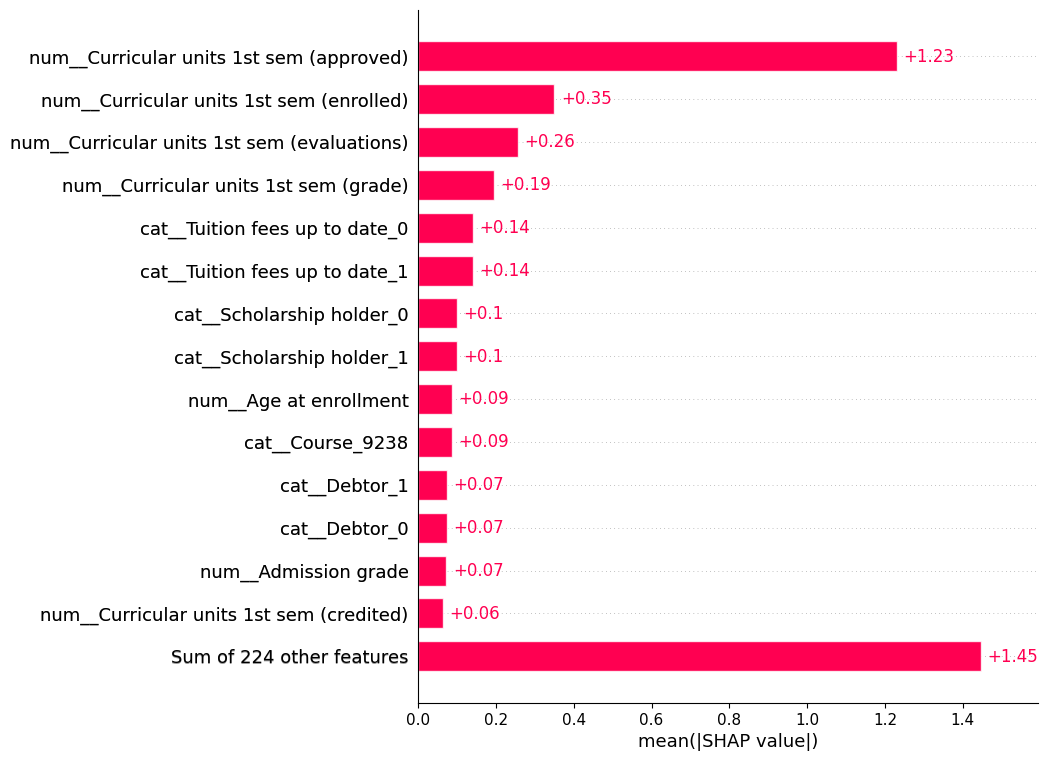

In [139]:
# SHAP analysis for Enrolled and Graduate

class_names = ["Dropout", "Enrolled", "Graduate"]

for class_index, class_name in enumerate(class_names):

    print(f"\nSHAP analysis for: {class_name}")

    class_shap = shap_values_full[:, :, class_index]

    shap.plots.bar(class_shap, max_display=15)


SHAP beeswarm: Dropout


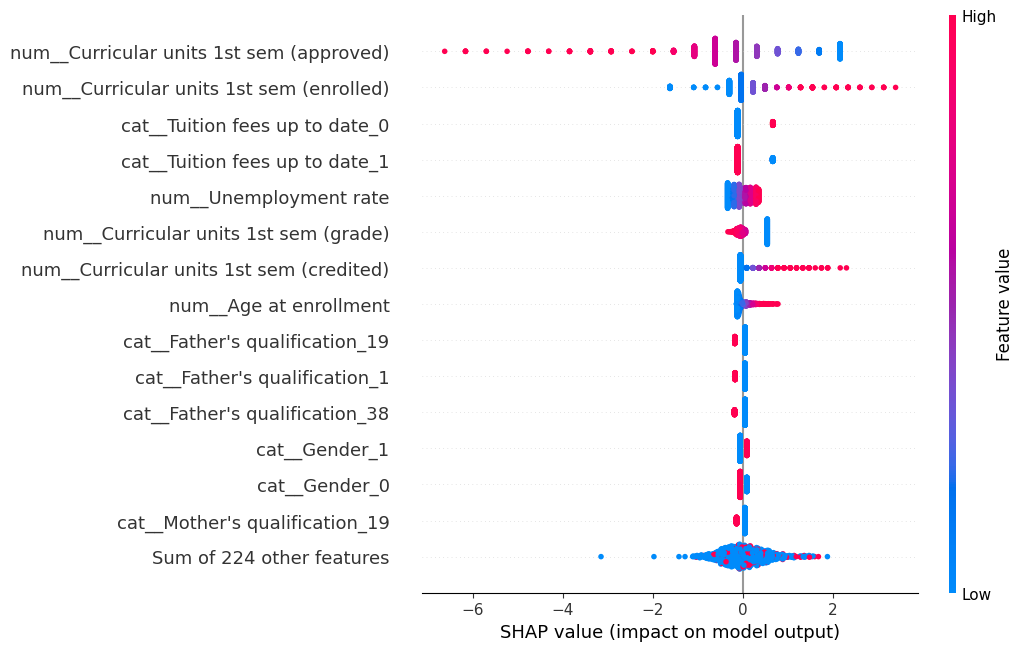


SHAP beeswarm: Enrolled


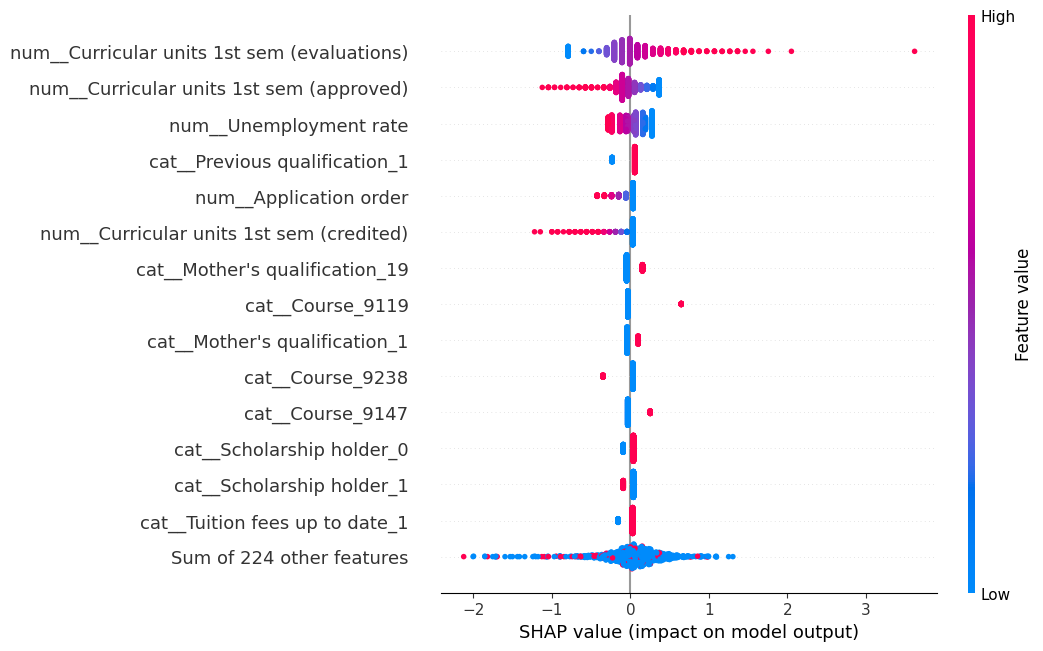


SHAP beeswarm: Graduate


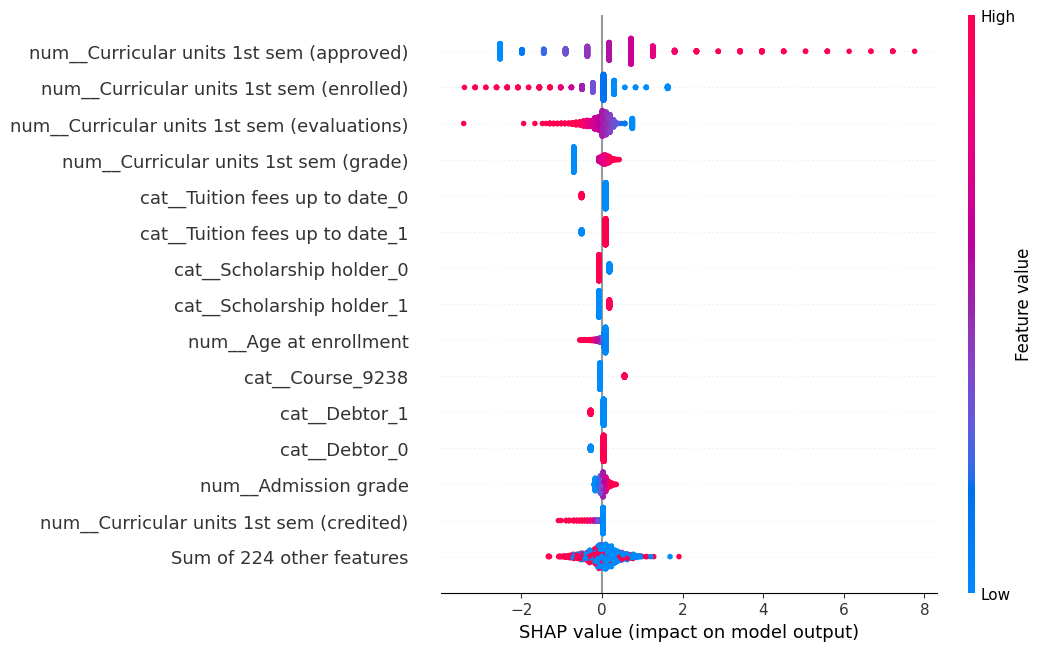

In [140]:
for class_index, class_name in enumerate(class_names):

    print(f"\nSHAP beeswarm: {class_name}")

    class_shap = shap_values_full[:, :, class_index]

    shap.plots.beeswarm(class_shap, max_display=15)

In [141]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Original Gender values in the test set
gender_test = X_test["Gender"].reset_index(drop=True)

# Align predictions with test observations
gender_test.index = range(len(gender_test))

y_test_reset = y_test.reset_index(drop=True)
y_pred_lr = best_lr_model.predict(X_test)

for gender_value in sorted(gender_test.unique()):

    mask = gender_test == gender_value

    print(f"\nGender = {gender_value}")
    print("Number of students:", mask.sum())

    print("Accuracy:",
          round(accuracy_score(
              y_test_reset[mask],
              y_pred_lr[mask]
          ), 3))

    print("Macro F1:",
          round(f1_score(
              y_test_reset[mask],
              y_pred_lr[mask],
              average="macro"
          ), 3))

    print(classification_report(
        y_test_reset[mask],
        y_pred_lr[mask],
        zero_division=0
    ))


Gender = 0
Number of students: 570
Accuracy: 0.73
Macro F1: 0.674
              precision    recall  f1-score   support

     Dropout       0.76      0.60      0.67       139
    Enrolled       0.44      0.62      0.51       101
    Graduate       0.85      0.82      0.83       330

    accuracy                           0.73       570
   macro avg       0.68      0.68      0.67       570
weighted avg       0.76      0.73      0.74       570


Gender = 1
Number of students: 315
Accuracy: 0.667
Macro F1: 0.633
              precision    recall  f1-score   support

     Dropout       0.84      0.71      0.77       145
    Enrolled       0.33      0.53      0.41        58
    Graduate       0.77      0.68      0.72       112

    accuracy                           0.67       315
   macro avg       0.65      0.64      0.63       315
weighted avg       0.72      0.67      0.69       315



In [142]:
from sklearn.metrics import accuracy_score, f1_score

y_test_reset = y_test.reset_index(drop=True)
gender_test = X_test["Gender"].reset_index(drop=True)

models = {
    "Logistic Regression": best_lr_model,
    "Random Forest": best_rf_model
}

for model_name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", "=" * 40)
    print(model_name)

    for gender_value in sorted(gender_test.unique()):

        mask = gender_test == gender_value

        accuracy = accuracy_score(
            y_test_reset[mask],
            predictions[mask]
        )

        macro_f1 = f1_score(
            y_test_reset[mask],
            predictions[mask],
            average="macro"
        )

        print(
            f"Gender {gender_value}: "
            f"Accuracy={accuracy:.3f}, "
            f"Macro F1={macro_f1:.3f}"
        )


Logistic Regression
Gender 0: Accuracy=0.730, Macro F1=0.674
Gender 1: Accuracy=0.667, Macro F1=0.633

Random Forest
Gender 0: Accuracy=0.742, Macro F1=0.668
Gender 1: Accuracy=0.679, Macro F1=0.629


In [143]:
import joblib
import os

# Create project directories
os.makedirs("student_dropout_project/models", exist_ok=True)
os.makedirs("student_dropout_project/reports", exist_ok=True)

# Save the trained models
joblib.dump(
    best_lr_model,
    "student_dropout_project/models/logistic_regression.pkl"
)

joblib.dump(
    best_rf_model,
    "student_dropout_project/models/random_forest.pkl"
)

print("Models saved successfully!")

Models saved successfully!
